# Exploração Visual da Camada `clean-data` (OpenAlex *Works*) com Spark SQL

Este caderno demonstra a **camada de consumo analítico interativo** da Prova de Conceito (*Laguna On-Premises PoC*), equivalente local ao uso combinado de **Amazon Athena** e **JupyterLab** sobre o lago de dados do **Projeto Laguna (UnB / IBICT, LaePeCBr)**.

> **Separação arquitetural:** os *pipelines* de ingestão, transformação (ETL) e *benchmark* são executados de forma não interativa via `spark-submit` (`jobs/etl_works.py` e `scripts/run_benchmark.py`), preservando o isolamento de memória entre repetições. Este notebook atua exclusivamente como cliente analítico de leitura sobre os arquivos colunares **Apache Parquet (Snappy)** já materializados em `s3a://clean-data/works/clean`.

## 1. Conexão ao *Cluster* Apache Spark *Standalone* e Leitura S3A

Inicializa uma `SparkSession` conectada ao `spark://spark-master:7077` e ao *gateway* S3 local do **SeaweedFS** (`http://seaweedfs:8333`) por meio do conector padronizado `S3AFileSystem`.

In [1]:
import os
import sys
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, "/opt/laguna/jobs")
from spark_session import build_spark_session

plt.rcParams.update({
    "figure.dpi": 130,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})

bucket_clean = os.environ.get("S3_BUCKET_CLEAN", "clean-data")
clean_path = f"s3a://{bucket_clean}/works/clean"

spark = build_spark_session("laguna-poc-notebook-analytics")
spark.sparkContext.setLogLevel("ERROR")

df_works = spark.read.parquet(clean_path)
df_works.createOrReplaceTempView("works_clean")

total_works = df_works.count()
resumo_conexao = pd.DataFrame([
    {"Métrica": "Caminho S3A lido", "Valor": clean_path},
    {"Métrica": "Motor de processamento", "Valor": f"Apache Spark {spark.version} (Standalone)"},
    {"Métrica": "Registros únicos na camada clean-data", "Valor": f"{total_works:,}".replace(",", ".")},
    {"Métrica": "Colunas de nível superior (Parquet)", "Valor": str(len(df_works.columns))},
    {"Métrica": "Partições lidas no DataFrame", "Valor": str(df_works.rdd.getNumPartitions())},
])
resumo_conexao

,Métrica,Valor
0,Caminho S3A lido,s3a://clean-data/works/clean
1,Motor de processamento,Apache Spark 3.5.3 (Standalone)
2,Registros únicos na camada clean-data,693
3,Colunas de nível superior (Parquet),51
4,Partições lidas no DataFrame,1


## 2. Inspeção do Esquema Colunar Parquet e Estruturas Aninhadas

Verifica o esquema preservado na camada `clean-data`, destacando tanto atributos escalares cientométricos quanto estruturas complexas (`struct`, `array` e o mapeamento explícito `map<string,array<int>>` aplicado a `abstract_inverted_index` para compatibilidade com Apache Parquet).

In [2]:
colunas_destaque = [
    "id", "doi", "title", "publication_year", "type",
    "cited_by_count", "open_access", "primary_location",
    "authorships", "referenced_works", "abstract_inverted_index",
]
mapa_tipos = {f.name: f.dataType.simpleString() for f in df_works.schema.fields}

df_esquema = pd.DataFrame([
    {
        "Coluna": col,
        "Categoria": "Escalar" if not any(mapa_tipos[col].startswith(p) for p in ("struct", "array", "map")) else "Aninhada / Complexa",
        "Tipo Parquet / Spark SQL (resumido)": (
            mapa_tipos[col] if len(mapa_tipos[col]) <= 78 else mapa_tipos[col][:75] + "..."
        ),
    }
    for col in colunas_destaque if col in mapa_tipos
])
df_esquema

,Coluna,Categoria,Tipo Parquet / Spark SQL (resumido)
0,id,Escalar,string
1,doi,Escalar,string
2,title,Escalar,string
3,publication_year,Escalar,bigint
4,type,Escalar,string
5,cited_by_count,Escalar,bigint
6,open_access,Aninhada / Complexa,"struct<any_repository_has_fulltext:boolean,is_..."
7,primary_location,Aninhada / Complexa,"struct<doi:string,id:string,is_accepted:boolea..."
8,authorships,Aninhada / Complexa,array<struct<affiliations:array<struct<institu...
9,referenced_works,Aninhada / Complexa,array<string>


## 3. Verificação Prática dos Princípios FAIR nos Metadados

No contexto do Projeto Laguna, a aderência aos princípios **FAIR (*Findable, Accessible, Interoperable, Reusable*)** manifesta-se na preservação de identificadores persistentes (**OpenAlex ID**, **DOI**, **ORCID** e **ROR**), metadados de acesso aberto/licenciamento e estrutura padronizada entre camadas.

In [3]:
df_fair_cobertura = spark.sql("""
    SELECT
        COUNT(*) AS total_registros,
        SUM(CASE WHEN id IS NOT NULL THEN 1 ELSE 0 END) AS com_openalex_id,
        SUM(CASE WHEN doi IS NOT NULL AND doi <> '' THEN 1 ELSE 0 END) AS com_doi,
        SUM(CASE WHEN size(authorships) > 0 THEN 1 ELSE 0 END) AS com_autorias,
        SUM(CASE WHEN exists(authorships, a -> a.author.orcid IS NOT NULL) THEN 1 ELSE 0 END) AS com_orcid_autor,
        SUM(CASE WHEN exists(authorships, a -> exists(a.institutions, i -> i.ror IS NOT NULL)) THEN 1 ELSE 0 END) AS com_ror_instituicao,
        SUM(CASE WHEN open_access.is_oa = true THEN 1 ELSE 0 END) AS em_acesso_aberto,
        SUM(CASE WHEN primary_location.license IS NOT NULL OR exists(locations, l -> l.license IS NOT NULL) THEN 1 ELSE 0 END) AS com_licenca_explicita
    FROM works_clean
""").toPandas()

tot = int(df_fair_cobertura["total_registros"].iloc[0])
metricas_fair = [
    ("Identificador OpenAlex (id)", int(df_fair_cobertura["com_openalex_id"].iloc[0])),
    ("Identificador DOI (doi)", int(df_fair_cobertura["com_doi"].iloc[0])),
    ("Lista de autorias estruturada (authorships)", int(df_fair_cobertura["com_autorias"].iloc[0])),
    ("Ao menos um autor com ORCID persistente", int(df_fair_cobertura["com_orcid_autor"].iloc[0])),
    ("Ao menos uma instituição com ROR persistente", int(df_fair_cobertura["com_ror_instituicao"].iloc[0])),
    ("Marcados como Acesso Aberto (open_access.is_oa)", int(df_fair_cobertura["em_acesso_aberto"].iloc[0])),
    ("Licença explícita de reuso informada (ex.: CC-BY)", int(df_fair_cobertura["com_licenca_explicita"].iloc[0])),
]

pd.DataFrame([
    {
        "Atributo FAIR verificado": nome,
        "Obras no recorte": qtd,
        "Cobertura (%)": f"{(qtd / tot) * 100:.1f}%",
    }
    for nome, qtd in metricas_fair
])

,Atributo FAIR verificado,Obras no recorte,Cobertura (%)
0,Identificador OpenAlex (id),693,100.0%
1,Identificador DOI (doi),670,96.7%
2,Lista de autorias estruturada (authorships),692,99.9%
3,Ao menos um autor com ORCID persistente,66,9.5%
4,Ao menos uma instituição com ROR persistente,41,5.9%
5,Marcados como Acesso Aberto (open_access.is_oa),78,11.3%
6,Licença explícita de reuso informada (ex.: CC-BY),41,5.9%


In [4]:
# Amostra real de registros higienizados na camada clean-data
df_amostra = spark.sql("""
    SELECT
        regexp_replace(id, 'https://openalex.org/', '') AS openalex_id,
        COALESCE(regexp_replace(doi, 'https://doi.org/', ''), '—') AS doi,
        publication_year AS ano,
        type AS tipo,
        COALESCE(open_access.oa_status, 'unknown') AS status_oa,
        COALESCE(cited_by_count, 0) AS citacoes,
        CASE
            WHEN length(title) > 65 THEN concat(substring(title, 1, 62), '...')
            ELSE title
        END AS titulo_resumido
    FROM works_clean
    WHERE title IS NOT NULL
    ORDER BY cited_by_count DESC, publication_year DESC
    LIMIT 8
""").toPandas()
df_amostra

,openalex_id,doi,ano,tipo,status_oa,citacoes,titulo_resumido
0,W3199387295,10.21917/ijsc.2019.0256,2019,article,diamond,28,DETECTION OF ACCURATE FACIAL DETECTION USING H...
1,W564822377,10.58837/chula.taic.3849,1966,book,closed,18,"Peasant and Nation, A Thai-Lao Village in a Th..."
2,W1593816996,10.66392/003777209814736556,2009,article,closed,17,Making Sense of Social Studies with Visualizat...
3,W336019492,10.1127/archiv-hydrobiol/103/1985/535,1985,article,closed,15,Differentiation of the coenoses of helminthes ...
4,W569378931,10.58837/chula.taic.2320,1967,book,closed,13,Asian social science bibliography : with annot...
5,W306207653,10.66392/003777210814735546,2010,article,closed,11,Education or Indoctrination? The Development o...
6,W1922107748,10.1183/13993003/erj.35.6.1425,2010,article,closed,10,Physiology and Practice of Pulmonary Function
7,W2267976361,10.2308/ah-1427820,1998,article,green,10,Financial Information and Quality Management--...


## 4. Consulta Spark SQL 1 — Distribuição por Tipologia Documental (`type`)

Agrega os registros da entidade *Works* segundo a tipologia documental indexada na OpenAlex.

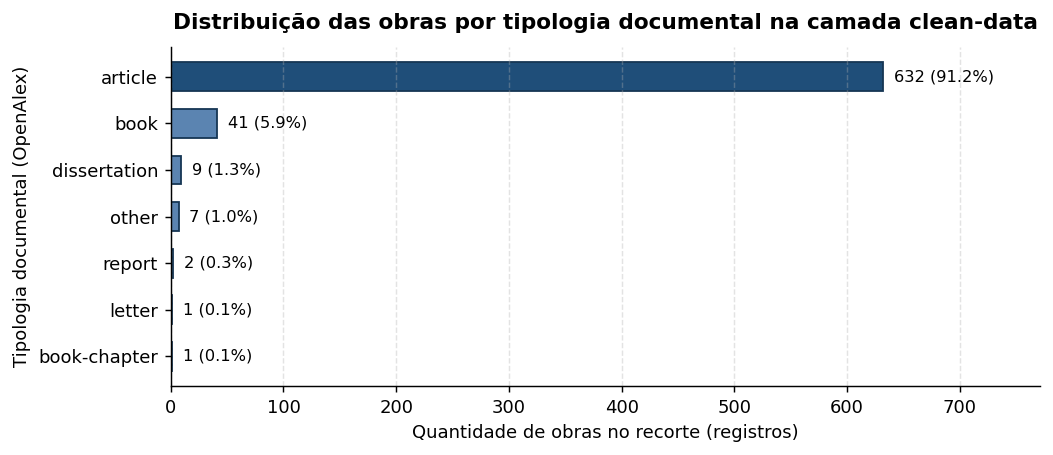

,tipo_documental,obras,percentual,total_citacoes
0,article,632,91.20,262
1,book,41,5.92,67
2,dissertation,9,1.30,4
3,other,7,1.01,0
4,report,2,0.29,0
5,letter,1,0.14,0
6,book-chapter,1,0.14,0


In [5]:
df_tipos = spark.sql("""
    SELECT
        COALESCE(type, 'não informado') AS tipo_documental,
        COUNT(*) AS obras,
        ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS percentual,
        COALESCE(SUM(cited_by_count), 0) AS total_citacoes
    FROM works_clean
    GROUP BY COALESCE(type, 'não informado')
    ORDER BY obras DESC
""").toPandas()

fig, ax = plt.subplots(figsize=(8.2, 3.6))
dados_plot = df_tipos.iloc[::-1]
cores = ["#1f4e79" if i == len(dados_plot) - 1 else "#5b84b1" for i in range(len(dados_plot))]
barras = ax.barh(dados_plot["tipo_documental"], dados_plot["obras"], color=cores, edgecolor="#163654", height=0.62)

ax.set_xlabel("Quantidade de obras no recorte (registros)")
ax.set_ylabel("Tipologia documental (OpenAlex)")
ax.set_title("Distribuição das obras por tipologia documental na camada clean-data", pad=10, fontweight="bold")
ax.set_xlim(0, dados_plot["obras"].max() * 1.22)
ax.grid(axis="x", linestyle="--", alpha=0.35)

for barra, (_, linha) in zip(barras, dados_plot.iterrows()):
    largura = barra.get_width()
    ax.text(
        largura + dados_plot["obras"].max() * 0.015,
        barra.get_y() + barra.get_height() / 2,
        f"{int(linha['obras'])} ({linha['percentual']:.1f}%)",
        va="center",
        fontsize=9,
    )

plt.tight_layout()
plt.show()

df_tipos

## 5. Consulta Spark SQL 2 — Distribuição Temporal das Publicações (`publication_year`)

Analisa a cobertura histórica do recorte ingerido por década de publicação e destaca os dez anos com maior concentração de registros.

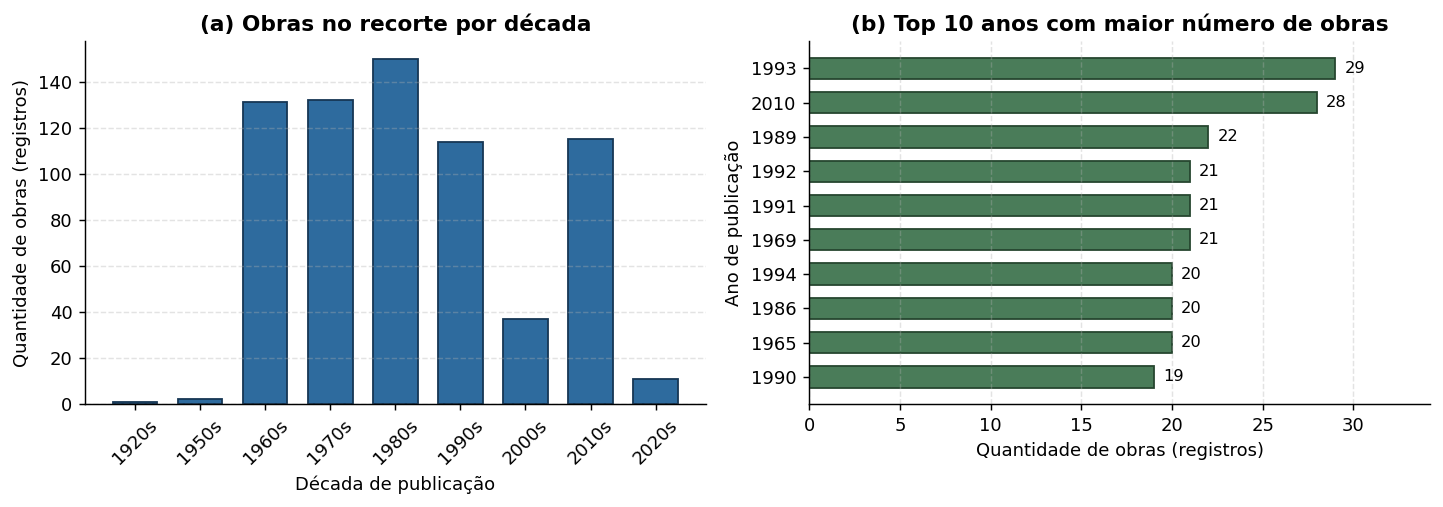

,ano_publicacao,obras,citacoes_acumuladas
0,1993,29,5
1,2010,28,34
2,1989,22,1
3,1992,21,4
4,1991,21,1
5,1969,21,8
6,1994,20,2
7,1986,20,2
8,1965,20,10
9,1990,19,0


In [6]:
df_decadas = spark.sql("""
    SELECT
        CONCAT(CAST(FLOOR(publication_year / 10) * 10 AS INT), 's') AS decada,
        CAST(FLOOR(publication_year / 10) * 10 AS INT) AS decada_ordem,
        COUNT(*) AS obras,
        COALESCE(SUM(cited_by_count), 0) AS citacoes
    FROM works_clean
    WHERE publication_year IS NOT NULL
    GROUP BY FLOOR(publication_year / 10)
    ORDER BY decada_ordem ASC
""").toPandas()

df_top_anos = spark.sql("""
    SELECT
        publication_year AS ano_publicacao,
        COUNT(*) AS obras,
        COALESCE(SUM(cited_by_count), 0) AS citacoes_acumuladas
    FROM works_clean
    WHERE publication_year IS NOT NULL
    GROUP BY publication_year
    ORDER BY obras DESC, publication_year DESC
    LIMIT 10
""").toPandas()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.2, 4.0))

ax1.bar(df_decadas["decada"], df_decadas["obras"], color="#2e6b9e", edgecolor="#163654", width=0.68)
ax1.set_title("(a) Obras no recorte por década", fontweight="bold")
ax1.set_xlabel("Década de publicação")
ax1.set_ylabel("Quantidade de obras (registros)")
ax1.tick_params(axis="x", rotation=45)
ax1.grid(axis="y", linestyle="--", alpha=0.35)

anos_str = df_top_anos["ano_publicacao"].astype(str).iloc[::-1]
obras_ano = df_top_anos["obras"].iloc[::-1]
barras2 = ax2.barh(anos_str, obras_ano, color="#4a7c59", edgecolor="#26462f", height=0.62)
ax2.set_title("(b) Top 10 anos com maior número de obras", fontweight="bold")
ax2.set_xlabel("Quantidade de obras (registros)")
ax2.set_ylabel("Ano de publicação")
ax2.set_xlim(0, obras_ano.max() * 1.18)
ax2.grid(axis="x", linestyle="--", alpha=0.35)

for b in barras2:
    w = b.get_width()
    ax2.text(w + 0.5, b.get_y() + b.get_height() / 2, f"{int(w)}", va="center", fontsize=9)

plt.tight_layout()
plt.show()

df_top_anos

## 6. Consulta Spark SQL 3 — Principais Fontes de Publicação (`primary_location.source`) e Citações

Consulta diretamente os atributos aninhados `primary_location.source.id` e `primary_location.source.display_name` no Parquet colunar, combinando volume publicado e soma de citações (`cited_by_count`).

> **Nota metodológica (efeito de lote em partições `updated_date`):** este recorte preliminar do TCC 1 foi selecionado pelas duas menores partições (`updated_date=2016-06-24` e `2025-07-24`) exclusivamente para validação técnica ponta a ponta do conector S3A e do esquema Parquet. A concentração de `470` obras (`67,8%`) em um mesmo periódico histórico belga ilustra empiricamente que partições diárias da OpenAlex frequentemente agrupam cargas em lote de uma mesma fonte ou editora — razão pela qual este recorte não deve ser interpretado como amostra bibliométrica representativa do catálogo global.

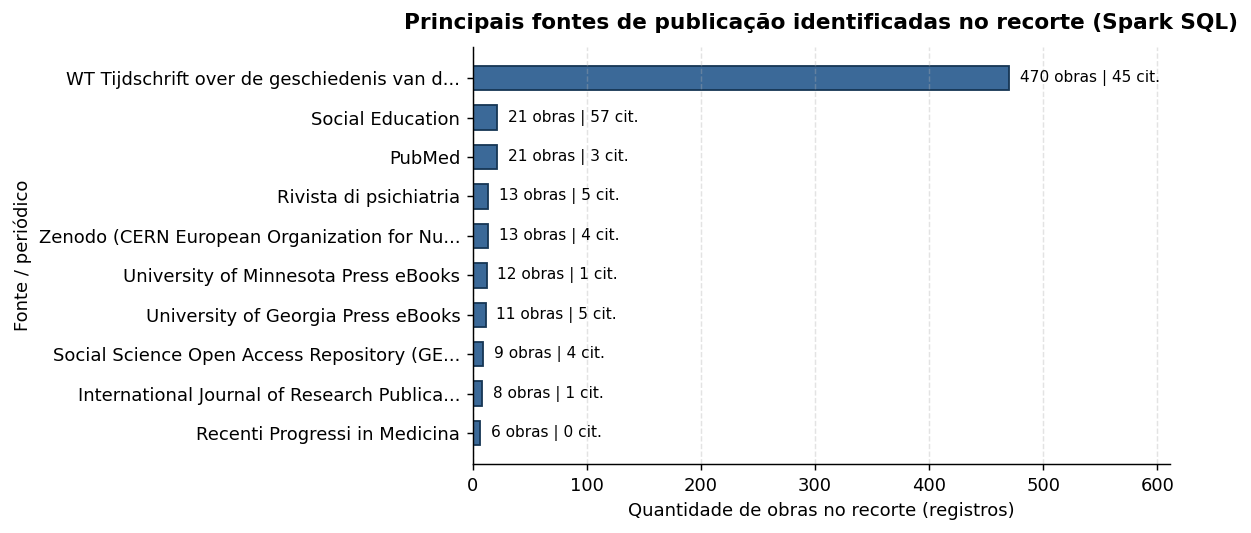

,source_id,fonte_publicacao,obras,total_citacoes
0,S4210219219,WT Tijdschrift over de geschiedenis van de Vla...,470,45
1,S7407058125,Social Education,21,57
2,S4306525036,PubMed,21,3
3,S28074187,Rivista di psichiatria,13,5
4,S4306400562,Zenodo (CERN European Organization for Nuclear...,13,4
5,S4306464182,University of Minnesota Press eBooks,12,1
6,S4306464162,University of Georgia Press eBooks,11,5
7,S4306401996,Social Science Open Access Repository (GESIS –...,9,4
8,S4210238074,International Journal of Research Publications,8,1
9,S2754753105,Recenti Progressi in Medicina,6,0


In [7]:
df_fontes = spark.sql("""
    SELECT
        regexp_replace(primary_location.source.id, 'https://openalex.org/', '') AS source_id,
        primary_location.source.display_name AS fonte_publicacao,
        COUNT(*) AS obras,
        COALESCE(SUM(cited_by_count), 0) AS total_citacoes
    FROM works_clean
    WHERE primary_location.source.display_name IS NOT NULL
    GROUP BY primary_location.source.id, primary_location.source.display_name
    ORDER BY obras DESC, total_citacoes DESC
    LIMIT 10
""").toPandas()

fig, ax = plt.subplots(figsize=(9.2, 4.2))
plot_f = df_fontes.iloc[::-1].copy()
plot_f["rotulo"] = plot_f["fonte_publicacao"].apply(lambda s: s if len(s) <= 44 else s[:41] + "...")

barras_f = ax.barh(plot_f["rotulo"], plot_f["obras"], color="#3b6998", edgecolor="#163654", height=0.62)
ax.set_xlabel("Quantidade de obras no recorte (registros)")
ax.set_ylabel("Fonte / periódico")
ax.set_title("Principais fontes de publicação identificadas no recorte (Spark SQL)", pad=10, fontweight="bold")
ax.set_xlim(0, plot_f["obras"].max() * 1.30)
ax.grid(axis="x", linestyle="--", alpha=0.35)

for b, (_, row) in zip(barras_f, plot_f.iterrows()):
    w = b.get_width()
    ax.text(
        w + plot_f["obras"].max() * 0.02,
        b.get_y() + b.get_height() / 2,
        f"{int(row['obras'])} obras | {int(row['total_citacoes'])} cit.",
        va="center",
        fontsize=8.5,
    )

plt.tight_layout()
plt.show()

df_fontes

## 7. Encerramento da Sessão Spark

Libera explicitamente os recursos dos *Executors* no *cluster* Spark *Standalone*.

In [8]:
spark.stop()
print("Sessão Spark encerrada e recursos liberados no cluster Standalone.")

Sessão Spark encerrada e recursos liberados no cluster Standalone.
